# Численное дифференцирование

Начнём с простейших разностных формул, затем выведем более общие формулы с помощью полиномиальной интерполяции и обсудим влияние погрешностей значений функции.

Предполагается, что интерполяционная задача для алгебраических полиномов и её основные свойства уже изучены.

**План лекции:** первая производная; вторая производная; формулы на основе интерполяции; другие способы аппроксимации; обусловленность и выбор шага.


## Простейшие формулы численного дифференцирования


### Вычисление первой производной

**Определение производной функции через предел.**

Пусть функция $f:U(x_0)\subset\mathbb R\to\mathbb R$ определена в некоторой окрестности $U(x_0)$ точки $x_0$.
Производной функции $f$ в точке $x_0$ называется следующий предел, если он существует:
$$
\begin{aligned}
f'(x_0)&=\lim_{x\to x_0}\frac{f(x)-f(x_0)}{x-x_0}\\
&=\lim_{\Delta x\to0}\frac{f(x_0+\Delta x)-f(x_0)}{\Delta x}
=\lim_{\Delta x\to0}\frac{\Delta f}{\Delta x}.
\end{aligned}\tag{1}
$$
Здесь $\Delta x\ne0$ — приращение аргумента, а $\Delta f=f(x_0+\Delta x)-f(x_0)$ — соответствующее приращение функции.
В произвольной точке $x$ то же определение даёт
$$
f'(x)=\lim_{\Delta x\to0}\frac{f(x+\Delta x)-f(x)}{\Delta x}.\tag{2}
$$

Зафиксируем шаг $h>0$. Все используемые ниже узлы должны принадлежать области определения $f$.
Заменяя стремящиеся к нулю приращения фиксированными значениями $h$ и $-h$, получаем две простейшие приближённые формулы.

**Определение 1. Правая разностная схема.**
$$
f'(x)\approx D_+f(x;h)=\frac{f(x+h)-f(x)}h.\tag{3}
$$

**Определение 2. Левая разностная схема.**
$$
f'(x)\approx D_-f(x;h)=\frac{f(x)-f(x-h)}h.\tag{4}
$$

Введём погрешности аппроксимации со знаком:
$$
r_+(x,h)=f'(x)-\frac{f(x+h)-f(x)}h,\tag{5}
$$
$$
r_-(x,h)=f'(x)-\frac{f(x)-f(x-h)}h.\tag{6}
$$
Знак определяется как **точное значение минус приближение**. Абсолютные погрешности равны $|r_+|$ и $|r_-|$.

**Оценка погрешности.** Предположим, что $f\in C^2([x-h,x+h])$, то есть функция имеет две непрерывные производные на этом отрезке. По формуле Тейлора
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(\xi_\pm)}2h^2,\tag{7}
$$
где $\xi_+\in(x,x+h)$ и $\xi_-\in(x-h,x)$.
Подставляя разложения в (5) и (6), получаем
$r_+=-f''(\xi_+)h/2$ и $r_-=f''(\xi_-)h/2$. Следовательно,
$$
|r_+(x,h)|\le\frac{M_{2,+}}2h,\qquad M_{2,+}=\max_{t\in[x,x+h]}|f''(t)|,\tag{8}
$$
$$
|r_-(x,h)|\le\frac{M_{2,-}}2h,\qquad M_{2,-}=\max_{t\in[x-h,x]}|f''(t)|.\tag{9}
$$
Для каждой односторонней формулы достаточно принадлежности классу $C^2$ только на соответствующем отрезке.
Обе формулы имеют порядок точности не ниже первого: для фиксированной гладкой функции погрешности равны $\mathcal O(h)$ при $h\to0$.


#### Геометрическая интерпретация

Пусть $N_0=(x,f(x))$, $N_-=(x-h,f(x-h))$ и $N_+=(x+h,f(x+h))$ — точки на графике функции.
Производная $f'(x)$ равна угловому коэффициенту касательной в точке $N_0$.
Правая и левая разности равны угловым коэффициентам секущих через точки $N_0,N_+$ и $N_-,N_0$ соответственно.
Центральная разность равна угловому коэффициенту секущей через $N_-,N_+$.

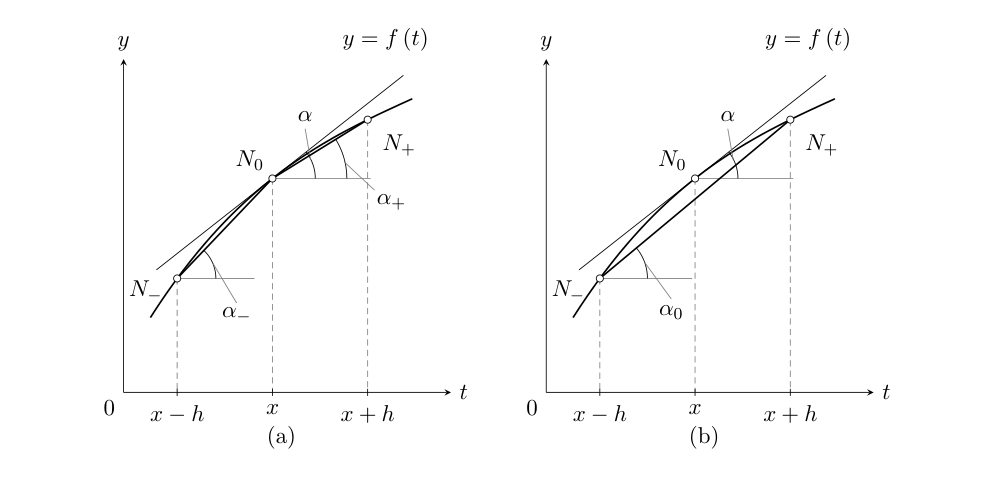

Центральная секущая не обязана проходить через $N_0$. Производную приближает её угловой коэффициент.


**Определение 3. Центральная разностная схема для первой производной.**
$$
f'(x)\approx D_0f(x;h)=\frac{f(x+h)-f(x-h)}{2h}.\tag{10}
$$

Оценим её погрешность со знаком:
$$
r_0(x,h)=f'(x)-\frac{f(x+h)-f(x-h)}{2h}.\tag{11}
$$
Предположим, что $f\in C^3([x-h,x+h])$. По формуле Тейлора
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(x)}2h^2
\pm\frac{f^{(3)}(\xi_\pm)}6h^3.\tag{12}
$$
При вычитании члены с чётными степенями приращения сокращаются, поэтому
$$
r_0(x,h)=-\frac{f^{(3)}(\xi_+)+f^{(3)}(\xi_-)}{12}h^2.\tag{13}
$$
Следовательно,
$$
|r_0(x,h)|\le\frac{M_3}{6}h^2,\qquad
M_3=\max_{t\in[x-h,x+h]}|f^{(3)}(t)|.\tag{14}
$$
Центральная формула имеет порядок точности не ниже второго.
Для этого улучшения необходимы как симметрия, так и указанная гладкость.

Формулы более высокого порядка получаются при использовании дополнительных узлов и сокращении большего числа членов разложения Тейлора.
Например, формула
$$
f'(x)\approx D_4f(x;h)=
\frac{f(x-2h)-8f(x-h)+8f(x+h)-f(x+2h)}{12h}\tag{15}
$$
имеет четвёртый порядок точности, если $f\in C^5$ в фиксированной окрестности, содержащей все используемые узлы.
Индекс $4$ здесь обозначает порядок точности.


**Пример 1.** Пусть $f(x)=e^x$ на отрезке $[0,1]$. Используем равномерную сетку с шагом $h=0.2$.
В вычислениях сохраняем полную точность значений с плавающей точкой; напечатанные десятичные знаки нужны только для отображения результатов.


In [1]:
import math

# Строим сетку по целочисленным индексам, чтобы не потерять правый конец
# из-за накопления ошибок при последовательном прибавлении шага.
a, b = 0.0, 1.0
n_intervals = 5
h = (b - a) / n_intervals
x_values = [a + i * h for i in range(n_intervals + 1)]
f_values = [math.exp(point) for point in x_values]

print(f"{'x':>5} {'f(x) = exp(x)':>18}")
print('-' * 24)
for point, value in zip(x_values, f_values):
    print(f"{point:5.1f} {value:18.9f}")


    x      f(x) = exp(x)
------------------------
  0.0        1.000000000
  0.2        1.221402758
  0.4        1.491824698
  0.6        1.822118800
  0.8        2.225540928
  1.0        2.718281828


In [2]:
# На концах используем односторонние разности, внутри — центральные.
n_nodes = len(x_values)
first_derivatives = []
print(f"{'x':>5} {'схема':>12} {'приближение':>16} {'точное':>16} {'абс. погрешность':>17}")
print('-' * 71)
for i, point in enumerate(x_values):
    if i == 0:
        approximation = (f_values[i + 1] - f_values[i]) / h
        method = 'правая'
    elif i == n_nodes - 1:
        approximation = (f_values[i] - f_values[i - 1]) / h
        method = 'левая'
    else:
        approximation = (f_values[i + 1] - f_values[i - 1]) / (2 * h)
        method = 'центральная'
    first_derivatives.append(approximation)
    exact = math.exp(point)
    print(f"{point:5.1f} {method:>12} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x        схема      приближение           точное  абс. погрешность
-----------------------------------------------------------------------
  0.0       правая      1.107013791      1.000000000      1.070138e-01
  0.2  центральная      1.229561744      1.221402758      8.158986e-03
  0.4  центральная      1.501790106      1.491824698      9.965408e-03
  0.6  центральная      1.834290577      1.822118800      1.217178e-02
  0.8  центральная      2.240407570      2.225540928      1.486664e-02
  1.0        левая      2.463704500      2.718281828      2.545773e-01


Априорные оценки можно вычислить до составления разностных отношений.
В точке $x=0$ формула (8) даёт
$$
|r_+(0,0.2)|\le\frac12 e^{0.2}(0.2)
\approx0.122140276.\tag{16}
$$
Это верхняя граница; фактическая абсолютная погрешность в таблице составляет примерно $0.107013791$.
В точке $x=0.2$ из формулы (14) получаем
$$
|r_0(0.2,0.2)|\le\frac16 e^{0.4}(0.2)^2
\approx0.009945498.\tag{17}
$$

В точках $x=0.4$ и $x=0.6$ доступны все четыре узла, необходимые для (15):
$$
f'(x)\approx
\frac{f(x-2h)-8f(x-h)+8f(x+h)-f(x+2h)}{12h}.\tag{18}
$$
Следующая таблица сравнивает результат этой формулы с точной производной.
Абсолютные погрешности составляют примерно $7.99\cdot10^{-5}$ и $9.76\cdot10^{-5}$.


In [3]:
# Первая производная четвёртого порядка: нужны два соседних узла с каждой стороны.
print(f"{'x':>5} {'4-й порядок':>16} {'точное':>16} {'абс. погрешность':>17}")
print('-' * 57)
for i in range(2, len(x_values) - 2):
    approximation = (f_values[i - 2] - 8*f_values[i - 1]
                     + 8*f_values[i + 1] - f_values[i + 2]) / (12*h)
    exact = math.exp(x_values[i])
    print(f"{x_values[i]:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x      4-й порядок           точное  абс. погрешность
---------------------------------------------------------
  0.4      1.491744754      1.491824698      7.994375e-05
  0.6      1.822021157      1.822118800      9.764351e-05


### Вычисление второй производной

**Определение 4. Центральная разностная схема для второй производной.**
$$
f''(x)\approx D_2f(x;h)=\frac{f(x-h)-2f(x)+f(x+h)}{h^2}.\tag{19}
$$
Здесь $D_2$ обозначает приближение второй производной.
Его погрешность со знаком равна
$$
r_2(x,h)=f''(x)-\frac{f(x-h)-2f(x)+f(x+h)}{h^2}.\tag{20}
$$
Предположим, что $f\in C^4([x-h,x+h])$. Подставляя разложения Тейлора
$$
f(x\pm h)=f(x)\pm f'(x)h+\frac{f''(x)}2h^2
\pm\frac{f^{(3)}(x)}6h^3+\frac{f^{(4)}(\xi_\pm)}{24}h^4\tag{21}
$$
получаем
$$
r_2(x,h)=-\frac{f^{(4)}(\xi_+)+f^{(4)}(\xi_-)}{24}h^2.\tag{22}
$$
Следовательно,
$$
|r_2(x,h)|\le\frac{M_4}{12}h^2,\qquad
M_4=\max_{t\in[x-h,x+h]}|f^{(4)}(t)|.\tag{23}
$$
Трёхузловая формула имеет порядок точности не ниже второго.

Пятиузловая формула имеет вид
$$
f''(x)\approx
\frac{-f(x-2h)+16f(x-h)-30f(x)+16f(x+h)-f(x+2h)}{12h^2}.\tag{24}
$$
Она имеет четвёртый порядок точности, если $f\in C^6$ в фиксированной окрестности, содержащей все пять узлов.


**Пример 2.** Используя те же значения $f(x)=e^x$ с полной точностью, найдём приближения $f''(x)$ во внутренних узлах по формуле (19).
Прочерк означает, что для центральной формулы требуется значение вне данной таблицы.


In [4]:
print(f"{'x':>5} {'3 узла':>16} {'точное':>16} {'абс. погрешность':>17}")
print('-' * 57)
second_derivatives_three = []
for i, point in enumerate(x_values):
    exact = math.exp(point)
    if i == 0 or i == len(x_values) - 1:
        second_derivatives_three.append(None)
        print(f"{point:5.1f} {'--':>16} {exact:16.9f} {'--':>17}")
    else:
        approximation = (f_values[i - 1] - 2*f_values[i] + f_values[i + 1]) / h**2
        second_derivatives_three.append(approximation)
        print(f"{point:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x           3 узла           точное  абс. погрешность
---------------------------------------------------------
  0.0               --      1.000000000                --
  0.2      1.225479533      1.221402758      4.076775e-03
  0.4      1.496804082      1.491824698      4.979384e-03
  0.6      1.828200634      1.822118800      6.081833e-03
  0.8      2.232969297      2.225540928      7.428368e-03
  1.0               --      2.718281828                --


**В граничных узлах.** Отсутствие центральной формулы не означает, что производную нельзя приближённо вычислить.
На равномерной сетке $x_j=a+jh$, $j=0,\ldots,n$, при $n\ge3$ можно использовать четырёхузловые односторонние формулы
$$
f''(x_0)\approx\frac{2y_0-5y_1+4y_2-y_3}{h^2},\qquad
f''(x_n)\approx\frac{2y_n-5y_{n-1}+4y_{n-2}-y_{n-3}}{h^2},\tag{25}
$$
где $y_j=f(x_j)$.
Они имеют второй порядок точности при $f\in C^4$ на соответствующих сжимающихся отрезках.
Эти формулы используют четыре узла, тогда как центральная формула использует три.


**Пример 2.1.** Применим пятиузловую формулу:
$$
f''(x)\approx
\frac{-f(x-2h)+16f(x-h)-30f(x)+16f(x+h)-f(x+2h)}{12h^2}.\tag{26}
$$
Это та же формула, что и (24). Для неё нужны два соседних узла с каждой стороны.


In [5]:
print(f"{'x':>5} {'5 узлов':>16} {'точное':>16} {'абс. погрешность':>17}")
print('-' * 57)
second_derivatives_five = []
for i, point in enumerate(x_values):
    exact = math.exp(point)
    if i < 2 or i > len(x_values) - 3:
        second_derivatives_five.append(None)
        print(f"{point:5.1f} {'--':>16} {exact:16.9f} {'--':>17}")
    else:
        approximation = (-f_values[i - 2] + 16*f_values[i - 1] - 30*f_values[i]
                         + 16*f_values[i + 1] - f_values[i + 2]) / (12*h**2)
        second_derivatives_five.append(approximation)
        print(f"{point:5.1f} {approximation:16.9f} {exact:16.9f} {abs(approximation - exact):17.6e}")


    x          5 узлов           точное  абс. погрешность
---------------------------------------------------------
  0.0               --      1.000000000                --
  0.2               --      1.221402758                --
  0.4      1.491798081      1.491824698      2.661622e-05
  0.6      1.822086291      1.822118800      3.250913e-05
  0.8               --      2.225540928                --
  1.0               --      2.718281828                --


Получаем
$$
f''(0.4)\approx1.491798081,\qquad f''(0.6)\approx1.822086291,\tag{27}
$$
с абсолютными погрешностями примерно $2.66\cdot10^{-5}$ и $3.25\cdot10^{-5}$.
Эти результаты согласованы с использованием полных, а не округлённых входных значений в коде.

Более высокий порядок не следует из малой погрешности при одном значении шага.
Для формулы четвёртого порядка уменьшение шага вдвое должно уменьшать погрешность аппроксимации примерно в $16$ раз, пока не становятся существенными ошибки округления.


In [6]:
# Проверка порядка пятиузловой формулы для второй производной при x = 0.4.
check_point = 0.4
previous_error = None
print(f"{'h':>9} {'абс. погрешность':>18} {'отношение ошибок':>19}")
print('-' * 48)
for check_step in [0.2, 0.1, 0.05, 0.025]:
    approximation = (-math.exp(check_point - 2*check_step)
                     + 16*math.exp(check_point - check_step)
                     - 30*math.exp(check_point)
                     + 16*math.exp(check_point + check_step)
                     - math.exp(check_point + 2*check_step)) / (12*check_step**2)
    error = abs(approximation - math.exp(check_point))
    ratio = '--' if previous_error is None else f'{previous_error / error:.5f}'
    print(f"{check_step:9.3f} {error:18.9e} {ratio:>19}")
    previous_error = error


        h   абс. погрешность    отношение ошибок
------------------------------------------------
    0.200    2.661622401e-05                  --
    0.100    1.659063671e-06            16.04292
    0.050    1.036219397e-07            16.01074
    0.025    6.475648684e-09            16.00179


## О выводе формул численного дифференцирования

Предположим, что в окрестности точки $x$ мы приближаем $f$ функцией $g$, производные которой легко вычисляются.
Для положительного целого $k$ естественно воспользоваться приближением
$$
f^{(k)}(x)\approx g^{(k)}(x).\tag{28}
$$
Малая погрешность значений функции сама по себе не гарантирует малой погрешности производной.
Необходимы также гладкость и подходящий способ аппроксимации.

### Формулы на основе полиномиальной интерполяции

Пусть $x_0<\cdots<x_n$ — различные узлы, $n\ge1$, а $P_n$ — полином степени **не выше** $n$, удовлетворяющий условиям $P_n(x_i)=f(x_i)$.
При $x\in[x_0,x_n]$ используем
$$
f^{(k)}(x)\approx P_n^{(k)}(x),\qquad 1\le k\le n.\tag{29}
$$

**Оценка погрешности.** Предположим, что $f\in C^{n+1}([x_0,x_n])$. Введём
$h_{\max}=\max_{0\le i<n}(x_{i+1}-x_i)$ и
$M_{n+1}=\max_{t\in[x_0,x_n]}|f^{(n+1)}(t)|$.
Тогда
$$
|f^{(k)}(x)-P_n^{(k)}(x)|
\le C_{n,k}M_{n+1}h_{\max}^{n+1-k},\qquad 1\le k\le n.\tag{30}
$$
Постоянные $C_{n,k}$ зависят от взаимного расположения узлов и точки вычисления производной.
Для равномерной оценки порядка необходимо, чтобы нормированная конфигурация при сжатии оставалась фиксированной или равномерно невырожденной.
Например, положим $H=x_n-x_0$ и введём нормированные узлы $\theta_i=(x_i-x_0)/H$; фиксированные различные $\theta_i$ обеспечивают ограниченность коэффициентов.
Один из способов доказательства — вычесть полином Тейлора степени $n$ с центром в $x$, проинтерполировать его остатки в узлах и продифференцировать полученное полиномиальное тождество.
Не следует дифференцировать неизвестную промежуточную точку в обычной формуле остатка интерполяции.

**Замечание 1.** Гарантированный порядок — **не ниже** $n+1-k$: число узлов интерполяции минус порядок производной.
Для некоторых функций или расположений узлов порядок может быть выше.

**Замечание 2.** Пусть узлы симметричны относительно точки вычисления производной, а $n-k$ чётно.
Следующий член разложения Тейлора сокращается, и порядок повышается как минимум до $n+2-k$, если $f\in C^{n+2}$ в фиксированной окрестности, содержащей сжимающиеся наборы узлов.
Примеры — центральные формулы (10), (15), (19) и (24).


#### Напоминание: интерполяционный полином Ньютона

Используя разделённые разности, запишем
$$
\begin{aligned}
P_n(x)&=f(x_0)+f[x_0,x_1](x-x_0)+\cdots\\
&\quad+f[x_0,\ldots,x_n](x-x_0)\cdots(x-x_{n-1})\\
&=\sum_{k=0}^n f[x_0,\ldots,x_k]\omega_k(x).
\end{aligned}\tag{31}
$$
Здесь $f[x_0]=f(x_0)$, $\omega_0(x)=1$, а
$\omega_k(x)=\prod_{j=0}^{k-1}(x-x_j)$ при $k\ge1$.

**Разделённые разности.** Обозначение в квадратных скобках $f[z_0,\ldots,z_k]$ означает разделённую разность на различных узлах, а не обычное значение функции.
Для упорядоченных выше узлов
$$
f[x_i,x_{i+1}]=\frac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i},\tag{32}
$$
$$
f[x_i,x_{i+1},x_{i+2}]=
\frac{f[x_{i+1},x_{i+2}]-f[x_i,x_{i+1}]}{x_{i+2}-x_i}.\tag{33}
$$
При $k\ge2$ и $0\le i\le n-k$
$$
f[x_i,\ldots,x_{i+k}]=
\frac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}{x_{i+k}-x_i}.\tag{34}
$$

**Таблица 1. Разделённые разности для четырёх узлов.** Для большего числа узлов таблица продолжается по тому же треугольному принципу.
$$
\begin{array}{c|c|c|c|c}
x&f(x)&\text{1-го порядка}&\text{2-го порядка}&\text{3-го порядка}\\\hline
x_0&f(x_0)&&&\\
&&f[x_0,x_1]&&\\
x_1&f(x_1)&&f[x_0,x_1,x_2]&\\
&&f[x_1,x_2]&&f[x_0,x_1,x_2,x_3]\\
x_2&f(x_2)&&f[x_1,x_2,x_3]&\\
&&f[x_2,x_3]&&\\
x_3&f(x_3)&&&
\end{array}\tag{35}
$$

**Свойства разделённых разностей.**

1. Разделённая разность симметрична по узлам: перестановка различных узлов не меняет её значения.
2. Если $f\in C^k([x_i,x_{i+k}])$ и $k\ge1$, то
$$
f[x_i,\ldots,x_{i+k}]=\frac{f^{(k)}(\xi)}{k!},
\qquad \xi\in(x_i,x_{i+k}).\tag{36}
$$
3. На равномерной сетке $x_i=a+ih$, где $y_i=f(x_i)$,
$f[x_i,\ldots,x_{i+k}]=\Delta^k y_i/(h^k k!)$.
Здесь $\Delta y_i=y_{i+1}-y_i$, а конечные разности более высоких порядков определяются рекурсивно.


#### Схема Эйткена–Невилла

Обозначим через $P_{(k,\ldots,m)}(x)$ полином степени не выше $m-k$, интерполирующий функцию в узлах $x_k,\ldots,x_m$.
Для одного узла $P_{(k)}(x)=y_k=f(x_k)$.
Тогда
$$
P_{(k,\ldots,m+1)}(x)=
\frac{(x-x_k)P_{(k+1,\ldots,m+1)}(x)
-(x-x_{m+1})P_{(k,\ldots,m)}(x)}{x_{m+1}-x_k}.\tag{37}
$$
Правая часть имеет степень не выше $m+1-k$ и принимает требуемые значения во всех узлах.
Из единственности интерполяции получаем эту рекуррентную формулу.

**Таблица 2. Вычисление по схеме Эйткена–Невилла для четырёх узлов.** Все элементы вычисляются при одном и том же выбранном $x$.
$$
\begin{array}{c|c|c|c}
\text{степень 0}&\text{степень 1}&\text{степень 2}&\text{степень 3}\\\hline
P_{(0)}=y_0&&&\\
&P_{(0,1)}&&\\
P_{(1)}=y_1&&P_{(0,1,2)}&\\
&P_{(1,2)}&&P_{(0,1,2,3)}\\
P_{(2)}=y_2&&P_{(1,2,3)}&\\
&P_{(2,3)}&&\\
P_{(3)}=y_3&&&
\end{array}\tag{38}
$$
Последний элемент равен значению $P_n(x)$. Схема позволяет вычислять значение интерполянта без явного раскрытия его коэффициентов.


#### Возвращаемся к формулам численного дифференцирования

Старший коэффициент в (31) равен $f[x_0,\ldots,x_n]$.
Поэтому $P_n^{(n)}(x)=n!f[x_0,\ldots,x_n]$, и
$$
f^{(n)}(x)\approx n!f[x_0,\ldots,x_n].\tag{39}
$$
При $f\in C^{n+1}$ и фиксированном взаимном расположении узлов, сжимающихся к $x$, из (30) следует порядок точности не ниже первого.
В частности,
$$
f'(x)\approx f[x_0,x_1]=\frac{f(x_1)-f(x_0)}{x_1-x_0},\tag{40}
$$
$$
f''(x)\approx2f[x_0,x_1,x_2]
=\frac{2}{x_2-x_0}
\left(\frac{f(x_2)-f(x_1)}{x_2-x_1}
-\frac{f(x_1)-f(x_0)}{x_1-x_0}\right).\tag{41}
$$
Эти формулы применимы и к неравномерно расположенным узлам.
Для произвольной точки $x$ в сжимающемся отрезке гарантирован первый порядок точности.
Симметрия может повысить порядок: так происходит для первой разности в середине отрезка и центральной второй разности.


### Использование таблиц с постоянным шагом

Пусть $x_i=x_0+ih$, $i=0,\ldots,n$, $h>0$, а $y_i=f(x_i)$.
Введём правые конечные разности $\Delta y_i=y_{i+1}-y_i$ и левые конечные разности $\nabla y_i=y_i-y_{i-1}$.
Разности более высоких порядков получаются повторным применением соответствующей операции.
Формула (39) принимает вид
$$
f^{(n)}(x)\approx\frac{\Delta^n y_0}{h^n}.\tag{42}
$$

На концах таблицы для симметричной формулы могут потребоваться недоступные значения.
Вместо неё продифференцируем интерполяционный полином в соответствующем граничном узле:
$$
f^{(k)}(x_0)\approx P_n^{(k)}(x_0),\qquad
f^{(k)}(x_n)\approx P_n^{(k)}(x_n).\tag{43}
$$
Для первой производной формулы Ньютона с правыми и левыми конечными разностями дают
$$
f'(x_0)\approx\frac1h\sum_{j=1}^n\frac{(-1)^{j-1}}j\Delta^j y_0,\tag{44}
$$
$$
f'(x_n)\approx\frac1h\sum_{j=1}^n\frac1j\nabla^j y_n.\tag{45}
$$
При фиксированном $n$ и $f\in C^{n+1}$ на соответствующих сжимающихся отрезках их порядок точности не ниже $n$.

При $n=2$ формула в левом граничном узле имеет вид
$$
f'(x_0)\approx\frac1h\left(\Delta y_0-\frac12\Delta^2 y_0\right).\tag{46}
$$
Поскольку $\Delta y_0=y_1-y_0$ и $\Delta^2 y_0=y_2-2y_1+y_0$,
$$
\begin{aligned}
f'(x_0)&\approx\frac1h\left[(y_1-y_0)-\frac12(y_2-2y_1+y_0)\right]\\
&=\frac{-3y_0+4y_1-y_2}{2h}.
\end{aligned}\tag{47}
$$
Итак,
$$
f'(x_0)\approx\frac{-3f(x_0)+4f(x_1)-f(x_2)}{2h}.\tag{48}
$$
В правом граничном узле
$$
f'(x_n)\approx\frac1h\left(\nabla y_n+\frac12\nabla^2y_n\right).\tag{49}
$$
Используя $\nabla y_n=y_n-y_{n-1}$ и $\nabla^2 y_n=y_n-2y_{n-1}+y_{n-2}$, получаем
$$
\begin{aligned}
f'(x_n)&\approx\frac1h\left[(y_n-y_{n-1})+\frac12(y_n-2y_{n-1}+y_{n-2})\right]\\
&=\frac{y_{n-2}-4y_{n-1}+3y_n}{2h}.
\end{aligned}\tag{50}
$$
Следовательно,
$$
f'(x_n)\approx\frac{f(x_{n-2})-4f(x_{n-1})+3f(x_n)}{2h}.\tag{51}
$$
Обе трёхузловые граничные формулы имеют второй порядок точности при $f\in C^3$.
Односторонние формулы тоже могут иметь высокий порядок; для этого нужны дополнительные узлы с доступной стороны.


### Другие подходы

**Дифференцирование сплайна.** Сплайн задаётся отдельно на каждом промежутке с определёнными условиями согласования в узлах сетки.
Если $S\in C^q([a,b])$, где $q$ — неотрицательное целое число, то $S^{(k)}$ непрерывна при $0\le k\le q$.
Одна только степень не определяет $q$.

Например, линейный интерполяционный сплайн нулевого уровня на $[x_i,x_{i+1}]$ имеет вид
$$
L_i(t)=\frac{x_{i+1}-t}{h_i}y_i+\frac{t-x_i}{h_i}y_{i+1},\qquad
h_i=x_{i+1}-x_i,\quad y_i=f(x_i).\tag{52}
$$
Внутри этого промежутка его производная равна $L_i'(t)=(y_{i+1}-y_i)/h_i$ — знакомому разностному отношению.
Составленный из таких частей линейный сплайн непрерывен, но его производная, вообще говоря, имеет скачки в узлах.
В середине промежутка его угловой коэффициент совпадает с центральной первой разностью с шагом $h_i/2$.

Кубический эрмитов сплайн согласует значения функции и первой производной в узлах и принадлежит классу $C^1$.
Классический кубический интерполяционный сплайн с подходящими граничными условиями принадлежит классу $C^2$.
Если производные для эрмитовой конструкции оцениваются по значениям функции, необходимо учитывать и погрешности этих оценок.
Например, конечные разности второго порядка дают знакомую центральную производную во внутреннем узле; сама по себе кубическая степень не делает эту оценку формулой четвёртого порядка.

**Дифференцирование локального приближения по МНК.** Метод наименьших квадратов уже изучен, поэтому рассмотрим только его применение здесь.
Приблизим соседние значения полиномом $p_x(t)=\sum_{j=0}^d a_j(t-x)^j$, используя не менее $d+1$ различных узлов и положительные веса.
Затем положим $f^{(k)}(x)\approx p_x^{(k)}(x)=k!a_k$ при $1\le k\le d$.
Использование большего числа наблюдений, чем коэффициентов, может уменьшить чувствительность к шуму ценой систематической погрешности аппроксимации.
Ширину окна и степень полинома нужно выбирать совместно.

Подробное построение сплайнов и дополнительные оценки оставим для раздаточного материала.


## Обусловленность формул численного дифференцирования

Пусть $f^*(t)$ — доступное приближение значения $f(t)$ в необходимом узле $t$.
Звёздочка отличает приближённые входные значения от точных.
Для правой разности полная погрешность со знаком равна
$$
\begin{aligned}
r^*(x,h)&=f'(x)-\frac{f^*(x+h)-f^*(x)}h\\
&=\underbrace{f'(x)-\frac{f(x+h)-f(x)}h}_{r_+(x,h)}\\
&\quad+\underbrace{\frac{[f(x+h)-f^*(x+h)]-[f(x)-f^*(x)]}h}_{r_F(x,h)}.
\end{aligned}\tag{53}
$$
Таким образом, полная погрешность состоит из **погрешности аппроксимации** $r_+$ и **погрешности, вызванной ошибками входных данных**, $r_F$.
Если в обоих узлах $|f^*(t)-f(t)|\le\delta$, где $\delta\ge0$ — граница абсолютной погрешности данных, то
$$
|r_F(x,h)|\le\frac{2\delta}h.\tag{54}
$$
Абсолютное число обусловленности правой разности равно $2/h$, если погрешность данных измеряется максимальным модулем ошибки входных значений.
При $h\to0$ оно растёт: вычитание близких значений и деление на малое число могут усиливать погрешности данных и округления.
Верхняя оценка может расти и тогда, когда фактические ошибки случайно компенсируются; расходимость каждой вычисленной погрешности из этого не следует.

**Оценка полной погрешности.** Зафиксируем допустимый шаг $h_0>0$ и предположим, что $f\in C^2([x,x+h_0])$.
Положим $M_2=\max_{t\in[x,x+h_0]}|f''(t)|$; эта величина не зависит от выбранного $0<h\le h_0$.
Объединяя (8) и (54), получаем
$$
|r^*(x,h)|\le\bar r(h)=\frac12M_2h+\frac{2\delta}h.\tag{55}
$$
При $M_2>0$ и $\delta>0$ минимизация этой верхней границы даёт
$$
\bar r'(h)=\frac12M_2-\frac{2\delta}{h^2},\tag{56}
$$
$$
h_{\mathrm{opt}}=2\sqrt{\frac{\delta}{M_2}},\tag{57}
$$
$$
\bar r(h_{\mathrm{opt}})=2\sqrt{\delta M_2}.\tag{58}
$$
Формула (57) задаёт минимум без ограничения на допустимый шаг. Если полученное значение больше $h_0$, используем $h_0$; формула (58) применима, когда минимум без ограничения достигается при допустимом шаге.
Если $\delta=0$, остаётся только погрешность аппроксимации. Если $M_2=0$ и $\delta>0$, оценка убывает с ростом $h$, поэтому выбираем наибольший допустимый шаг.

Шаг, оптимальный для этой оценки, не обязан минимизировать фактическую погрешность вычислений с плавающей точкой.
Практический вывод: уменьшение $h$ не всегда улучшает результат.


**Пример 3. Погрешности аппроксимации и округления.** Пусть $f(x)=e^x$. Приблизим $f'(1)=e$ при различных шагах.
Прямое разностное отношение теряет точность при очень малых $h$.
Для сравнения: тождество $e^{1+h}-e=e\,(e^h-1)$ позволяет провести вычисление с помощью `math.expm1(h)`, которая вычисляет $e^h-1$ с высокой точностью вблизи нуля.
Это специальное преобразование для выбранной функции.
Сравнение показывает влияние потери точности при вычитании близких чисел; для произвольных табличных данных такое преобразование может быть недоступно.


In [7]:
evaluation_point = 1.0
exact_derivative = math.exp(evaluation_point)
demo_steps = [10.0**(-k) for k in range(1, 17)]

print(f"{'h':>10} {'прямая формула':>18} {'абс. погрешность':>17} {'ошибка expm1':>17}")
print('-' * 66)
roundoff_results = []
for demo_step in demo_steps:
    direct = (math.exp(evaluation_point + demo_step)
              - math.exp(evaluation_point)) / demo_step
    stable = math.exp(evaluation_point) * math.expm1(demo_step) / demo_step
    direct_error = abs(direct - exact_derivative)
    stable_error = abs(stable - exact_derivative)
    roundoff_results.append((demo_step, direct, direct_error, stable_error))
    print(f"{demo_step:10.0e} {direct:18.10f} {direct_error:17.6e} {stable_error:17.6e}")

print('\nПри h = 1e-16 отличается ли сохранённое значение 1 + h от 1?')
print('Да' if evaluation_point + demo_steps[-1] != evaluation_point else 'Нет')


         h     прямая формула  абс. погрешность      ошибка expm1
------------------------------------------------------------------
     1e-01       2.8588419549      1.405601e-01      1.405601e-01
     1e-02       2.7319186558      1.363683e-02      1.363683e-02
     1e-03       2.7196414225      1.359594e-03      1.359594e-03
     1e-04       2.7184177471      1.359186e-04      1.359186e-04
     1e-05       2.7182954200      1.359150e-05      1.359145e-05
     1e-06       2.7182831874      1.358972e-06      1.359141e-06
     1e-07       2.7182819684      1.399467e-07      1.359141e-07
     1e-08       2.7182818219      6.602751e-09      1.359141e-08
     1e-09       2.7182820439      2.154419e-07      1.359141e-09
     1e-10       2.7182833762      1.547709e-06      1.359139e-10
     1e-11       2.7183144624      3.263395e-05      1.359179e-11
     1e-12       2.7187141427      4.323142e-04      1.358913e-12
     1e-13       2.7178259643      4.558642e-04      1.358913e-13
     1e-1

Как правило, наименьшая погрешность достигается при некотором промежуточном шаге.
Последние строки показывают, почему определение производной через предел не означает, что в вычислениях нужно брать наименьшее представимое приращение.
Конкретные результаты этого эксперимента с плавающей точкой могут немного различаться на разных платформах.

**Что следует проверять на практике?** Предположения о гладкости и погрешностях данных, результаты при нескольких значениях шага и доступность всех необходимых узлов.
При зашумлённых данных стоит рассмотреть сглаживание или регуляризацию вместо безусловного уменьшения шага.


## Литература

1. **Н. С. Бахвалов, Н. П. Жидков, Г. М. Кобельков.** *Численные методы.* М.: Наука, 1987.
2. **R. L. Burden, J. D. Faires, A. M. Burden.** *Numerical Analysis.* 10th edition. Boston: Brooks/Cole, 2015.
3. **А. Н. Тихонов, В. Я. Арсенин.** *Методы решения некорректных задач.* М.: Наука, 1986.
4. **H. W. Engl, M. Hanke, A. Neubauer.** *Regularization of Inverse Problems.* Dordrecht: Kluwer Academic Publishers, 1996.
5. **Н. Н. Калиткин.** *Численные методы.* М.: Наука, 1978.
6. **V. N. Kaliakin.** *Introduction to Approximate Solution Techniques, Numerical Modeling, and Finite Element Methods.* Boca Raton: CRC Press, 2002.
